<a href="https://colab.research.google.com/github/uavinash15/DataScience-/blob/main/DeepLearning/Neural%20Networks/MAE_MSE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# mlp for regression with mae loss function
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import SGD
from matplotlib import pyplot


In [2]:
# generate regression dataset
X, y = make_regression(n_samples=1000, n_features=20, noise=0.1, random_state=1)

In [5]:
print(X.shape,y.shape)

(1000, 20) (1000,)


In [6]:
# standardize dataset
X = StandardScaler().fit_transform(X)
y = StandardScaler().fit_transform(y.reshape(len(y),1))[:,0]

In [7]:
X

array([[ 0.64516745,  0.76000873, -0.18010938, ..., -0.76479647,
        -0.2088517 ,  1.04702956],
       [ 1.91668806, -0.46635771,  1.19569536, ..., -0.70196101,
         0.04332125,  0.27556296],
       [-0.06519522,  0.31264841, -1.83288453, ...,  0.37878977,
        -0.16435327,  0.65283426],
       ...,
       [-0.15471527, -0.27429653, -1.35192974, ...,  0.67848377,
        -0.21611277, -0.84236813],
       [-1.07225152, -0.16523037,  0.48553115, ..., -0.02186635,
         1.48243756,  1.74981514],
       [-1.24570623, -0.19130146,  0.60895001, ...,  2.72939424,
        -1.42222369, -0.20585159]])

In [8]:
y

array([ 1.83574387e+00,  6.56329482e-01, -1.21592690e+00,  9.52206978e-01,
       -4.68122128e-01, -4.59302209e-01,  1.90332494e-01, -1.63280948e-01,
        1.71851832e+00,  3.50552363e-01,  3.80122188e-02,  2.25844817e-01,
       -1.44965282e+00, -5.17236076e-01, -1.07167362e+00,  8.03362439e-01,
       -3.14702032e-01, -4.06063394e-02, -1.55942047e-01, -2.71671889e+00,
       -8.16698122e-02, -5.49399977e-01,  6.33706753e-01,  4.04819740e-01,
       -8.59670790e-03, -9.73955140e-01, -1.93646428e-01, -4.34250850e-01,
       -8.67713637e-01,  1.69909973e+00,  2.89540715e-01,  8.25950917e-01,
       -6.42018431e-01, -3.26253830e-02, -1.43807638e+00,  4.14891856e-01,
        6.14365202e-01,  8.15051349e-01, -4.70197731e-01, -1.13788656e-01,
        7.68132228e-01,  4.96716622e-01, -7.95202475e-01, -1.76950561e+00,
       -8.37314391e-01,  3.03722071e-01,  1.38500842e+00, -6.16783769e-01,
       -8.88615990e-01, -4.22205036e-01, -7.15628695e-01,  6.19515110e-01,
        1.27783916e+00, -

In [9]:
print(X.shape,y.shape)

(1000, 20) (1000,)


split into train and test

In [10]:
n_train = 500
trainX, testX = X[:n_train, :], X[n_train:, :]
trainy, testy = y[:n_train], y[n_train:]

In [11]:
print(trainX.shape,testX.shape,trainy.shape,testy.shape)

(500, 20) (500, 20) (500,) (500,)


In [12]:
# define model
model = Sequential()
model.add(Dense(25, input_dim=20, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(1, activation='linear'))
opt = SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss='mean_absolute_error', optimizer=opt, metrics=['mse'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
# fit model
history = model.fit(trainX, trainy, validation_data=(testX, testy), epochs=100, verbose=0)

In [14]:
# evaluate the model
_, train_mse = model.evaluate(trainX, trainy, verbose=0)
_, test_mse = model.evaluate(testX, testy, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_mse, test_mse))

Train: 0.001, Test: 0.001


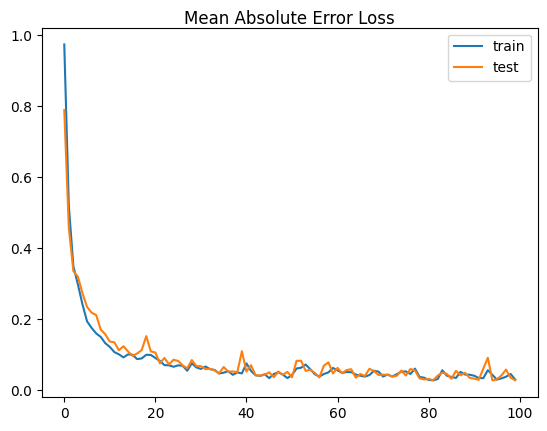

In [15]:
# plot loss during training
pyplot.title('Mean Absolute Error Loss', pad=-20)
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.legend()

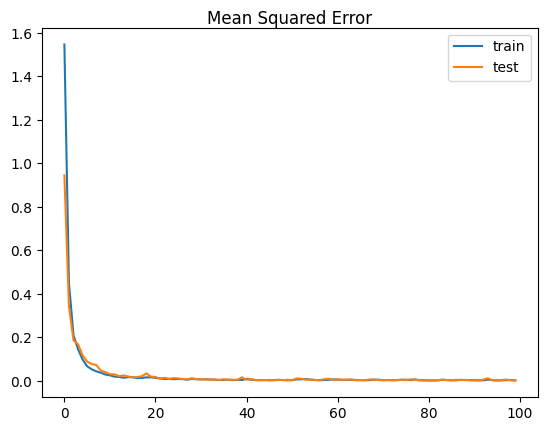

In [16]:
# plot mse during training
pyplot.title('Mean Squared Error', pad=-20)
pyplot.plot(history.history['mse'], label='train')
pyplot.plot(history.history['val_mse'], label='test')
pyplot.legend()
pyplot.show()